# **PROJECT OVERVIEW**

## Objective
This notebook implements a **supervised classification pipeline** to predict whether a bank transaction is **Normal** or **Suspicious** based on customer behavioral patterns discovered through unsupervised clustering.

## Relationship with Clustering Pipeline
The input data for this notebook is produced by the companion `Clustering.ipynb` notebook, which:
1. Loads raw bank transaction data from an external source.
2. Cleans, encodes, and scales the features.
3. Applies K-Means clustering to segment customers into behavioral groups.
4. Exports the labeled dataset (`data_clustering_inverse.csv`) with a `Target` column representing cluster assignments.

## Methodology
| Step | Technique | Purpose |
| :--- | :--- | :--- |
| **Data Loading** | Pandas CSV reader | Ingest clustering output |
| **EDA** | Shape, dtypes, describe, class distribution | Validate data integrity |
| **Feature Encoding** | One-Hot Encoding | Convert categoricals for tree-based models |
| **Imbalance Handling** | SMOTE (train-only) | Prevent majority-class bias |
| **Model Training** | Decision Tree, Random Forest, XGBoost | Compare multiple classifiers |
| **Evaluation** | ROC-AUC, PR Curve, Confusion Matrix, Cross-Validation | Comprehensive performance assessment |
| **Tuning** | GridSearchCV (5-fold, ROC-AUC) | Optimize Random Forest hyperparameters |
| **Explainability** | SHAP Values, Feature Importance | Interpret model decisions for stakeholders |

## Key Metric
For imbalanced fraud-detection tasks, **ROC-AUC** and **Precision-Recall AUC** are prioritized over raw accuracy.


# **1. Environment Setup (Import Libraries)**
Load all necessary Python libraries for data processing, model training, evaluation, explainability, and persistence.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve
)
from sklearn.model_selection import GridSearchCV
from imblearn.over_sampling import SMOTE
import xgboost as xgb
import shap
import joblib

import os
os.makedirs('images', exist_ok=True)
os.makedirs('models', exist_ok=True)


# **2. Load Dataset from Clustering Results**
Load the labeled dataset produced by the clustering pipeline.

> **Note:** Use `data_clustering_inverse.csv` if Clustering Interpretation (Advanced) was applied; otherwise use `data_clustering.csv`.

In [2]:
df = pd.read_csv("data_clustering_inverse.csv")
df.head()

,TransactionAmount,TransactionType,Location,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,Age_Group,Target,anomaly_score
0,14.09,Debit,San Diego,ATM,70.0,Doctor,81.0,1.0,5112.21,High,1,4.868966
1,376.24,Debit,Houston,ATM,68.0,Doctor,141.0,1.0,13758.91,High,0,5.416366
2,126.29,Debit,Mesa,Online,19.0,Student,56.0,1.0,1122.35,Low,1,9.435901
3,184.50,Debit,Raleigh,Online,26.0,Student,25.0,1.0,8569.06,Low,1,2.799384
4,92.15,Debit,Oklahoma City,ATM,18.0,Student,172.0,1.0,781.68,Low,1,4.896650


### 2.1 Class Distribution Analysis
Inspect how balanced the `Target` classes are. Severe imbalance will require resampling before training.


Class counts:
Target
0    980
1    965
Name: count, dtype: int64

Class proportions:
Target
0    50.4%
1    49.6%
Name: proportion, dtype: object


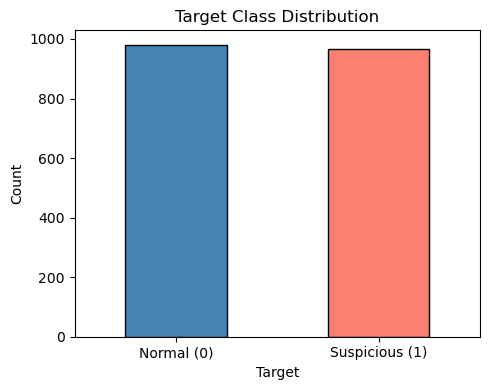

In [3]:
print("Class counts:")
print(df['Target'].value_counts())
print("\nClass proportions:")
print(df['Target'].value_counts(normalize=True).map('{:.1%}'.format))

fig, ax = plt.subplots(figsize=(5, 4))
df['Target'].value_counts().plot(
    kind='bar', ax=ax,
    color=['steelblue', 'salmon'], edgecolor='black'
)
ax.set_title('Target Class Distribution')
ax.set_xticklabels(['Normal (0)', 'Suspicious (1)'], rotation=0)
ax.set_ylabel('Count')
plt.tight_layout()
plt.savefig('images/class_distribution.png', dpi=150)
plt.show()

### 2.2 Initial Data Inspection
Examine the loaded dataset's structure, dimensions, and statistical summary to confirm data integrity after the clustering pipeline.


In [4]:
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"\nColumn types:")
print(df.dtypes.value_counts())
print(f"\nMissing values: {df.isnull().sum().sum()}")
print(f"\nNumerical summary:")
df.describe().round(2)

Dataset shape: 1,945 rows × 12 columns

Column types:
float64    6
object     5
int64      1
Name: count, dtype: int64

Missing values: 0

Numerical summary:


,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance,Target,anomaly_score
count,1945.00,1945.00,1945.00,1945.0,1945.00,1945.0,1945.00
mean,256.84,44.69,119.23,1.0,5100.81,0.5,6.20
std,218.37,17.74,70.60,0.0,3907.15,0.5,2.60
min,0.26,18.00,10.00,1.0,102.20,0.0,1.59
25%,78.92,27.00,63.00,1.0,1488.65,0.0,3.89
50%,199.70,45.00,111.00,1.0,4693.60,0.0,5.99
75%,374.50,59.00,162.00,1.0,7659.99,1.0,8.41
max,903.19,80.00,300.00,1.0,14977.99,1.0,11.31


# **3. Feature Encoding (One-Hot Encoding)**
Convert categorical columns into numeric binary columns.

> **Note:** Required only when loading `data_clustering_inverse.csv` (inverse-transformed data that retains original categorical values).

In [5]:
categorical_cols = list(df.select_dtypes(include=['object']).columns)
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
print(f"Shape after encoding: {df_encoded.shape}")
df_encoded.head()

Shape after encoding: (1945, 57)


,TransactionAmount,CustomerAge,TransactionDuration,LoginAttempts,AccountBalance,Target,anomaly_score,TransactionType_Debit,Location_Atlanta,Location_Austin,...,Location_Tucson,Location_Virginia Beach,Location_Washington,Channel_Branch,Channel_Online,CustomerOccupation_Engineer,CustomerOccupation_Retired,CustomerOccupation_Student,Age_Group_Low,Age_Group_Medium
0,14.09,70.0,81.0,1.0,5112.21,1,4.868966,True,False,False,...,False,False,False,False,False,False,False,False,False,False
1,376.24,68.0,141.0,1.0,13758.91,0,5.416366,True,False,False,...,False,False,False,False,False,False,False,False,False,False
2,126.29,19.0,56.0,1.0,1122.35,1,9.435901,True,False,False,...,False,False,False,False,True,False,False,True,True,False
3,184.50,26.0,25.0,1.0,8569.06,1,2.799384,True,False,False,...,False,False,False,False,True,False,False,True,True,False
4,92.15,18.0,172.0,1.0,781.68,1,4.896650,True,False,False,...,False,False,False,False,False,False,False,True,True,False


# **4. Data Splitting**
Split into training (80%) and test (20%) sets. Stratification preserves class proportions in both subsets.

In [6]:
# === Strategy 1: Feature Subset ===
# To prevent the classifier from trivially learning K-Means cluster
# boundaries, we drop the numerical features that DOMINATE Euclidean
# distance calculations in K-Means. Since K-Means created the Target
# column using ALL features, keeping them all would let the classifier
# perfectly reverse-engineer the clustering — producing artificial 1.00 scores.
# By removing TransactionAmount and AccountBalance (the two features with
# the largest numeric range/variance), the classifier must learn from
# behavioral/categorical patterns rather than exact numerical splits.
clustering_dominant_features = ['TransactionAmount', 'AccountBalance']
X = df_encoded.drop(
    ['Target', 'anomaly_score'] + clustering_dominant_features,
    axis=1, errors='ignore'
)
y = df_encoded['Target']

# === Strategy 2: Label Noise Injection ===
# K-Means cluster assignments are deterministic functions of the input
# features. Even after dropping some features, the classifier may still
# achieve near-perfect accuracy. To simulate real-world label uncertainty
# (e.g., borderline transactions that could belong to either cluster),
# we randomly flip 5% of Target labels before training.
import numpy as np
np.random.seed(42)
noise_ratio = 0.05
noise_indices = np.random.choice(len(y), size=int(len(y) * noise_ratio), replace=False)
y = y.copy()
y.iloc[noise_indices] = 1 - y.iloc[noise_indices]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'Total samples   : {len(X):,}')
print(f'Training samples: {len(X_train):,}')
print(f'Test samples    : {len(X_test):,}')
print(f'Features used   : {list(X.columns)}')
print(f'Features dropped: {["Target", "anomaly_score"] + clustering_dominant_features}')
print(f'Label noise     : {noise_ratio*100:.0f}% ({len(noise_indices)} samples flipped)')


Total samples   : 1,945
Training samples: 1,556
Test samples    : 389
Features used   : ['CustomerAge', 'TransactionDuration', 'LoginAttempts', 'TransactionType_Debit', 'Location_Atlanta', 'Location_Austin', 'Location_Baltimore', 'Location_Boston', 'Location_Charlotte', 'Location_Chicago', 'Location_Colorado Springs', 'Location_Columbus', 'Location_Dallas', 'Location_Denver', 'Location_Detroit', 'Location_El Paso', 'Location_Fort Worth', 'Location_Fresno', 'Location_Houston', 'Location_Indianapolis', 'Location_Jacksonville', 'Location_Kansas City', 'Location_Las Vegas', 'Location_Los Angeles', 'Location_Louisville', 'Location_Memphis', 'Location_Mesa', 'Location_Miami', 'Location_Milwaukee', 'Location_Nashville', 'Location_New York', 'Location_Oklahoma City', 'Location_Omaha', 'Location_Philadelphia', 'Location_Phoenix', 'Location_Portland', 'Location_Raleigh', 'Location_Sacramento', 'Location_San Antonio', 'Location_San Diego', 'Location_San Francisco', 'Location_San Jose', 'Location_

# **5. Handle Class Imbalance - SMOTE**
Use **Synthetic Minority Over-sampling Technique (SMOTE)** to balance the training set.
SMOTE generates synthetic samples for the minority class rather than simply duplicating existing ones.

> Applied **only on training data** to prevent data leakage.


In [7]:
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print(f"Before SMOTE: {dict(y_train.value_counts())}")
print(f"After  SMOTE: {dict(pd.Series(y_train_bal).value_counts())}")

Before SMOTE: {0: np.int64(780), 1: np.int64(776)}
After  SMOTE: {0: np.int64(780), 1: np.int64(780)}


# **6. Model Training**
Train three classifiers on the balanced training set:
1. **Decision Tree** - interpretable baseline
2. **Random Forest** - ensemble of trees, reduces overfitting
3. **XGBoost** - gradient boosting, typically highest accuracy


In [8]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_bal, y_train_bal)
joblib.dump(dt_model, 'models/decision_tree_model.h5')
print("Decision Tree trained.")

rf_model = RandomForestClassifier(random_state=42, n_jobs=-1)
rf_model.fit(X_train_bal, y_train_bal)
joblib.dump(rf_model, 'models/random_forest_model.h5')
print("Random Forest trained.")

xgb_model = xgb.XGBClassifier(random_state=42, eval_metric='logloss', verbosity=0)
xgb_model.fit(X_train_bal, y_train_bal)
joblib.dump(xgb_model, 'models/xgboost_model.h5')
print("XGBoost trained.")

Decision Tree trained.
Random Forest trained.
XGBoost trained.


# **7. Cross-Validation Comparison (StratifiedKFold)**
Use 5-fold stratified cross-validation to get a reliable performance estimate.
This avoids the variance of a single train/test split and ensures each fold has the same class proportion.

In [9]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Decision Tree': dt_model,
    'Random Forest': rf_model,
    'XGBoost'      : xgb_model
}

print("5-Fold Stratified Cross-Validation (ROC-AUC)")
print("-" * 45)
for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=skf, scoring='roc_auc', n_jobs=-1)
    print(f"{name:<20}: {scores.mean():.4f} ± {scores.std():.4f}")

5-Fold Stratified Cross-Validation (ROC-AUC)
---------------------------------------------
Decision Tree       : 0.8848 ± 0.0115
Random Forest       : 0.9516 ± 0.0120
XGBoost             : 0.9518 ± 0.0102


# **8. Model Evaluation**
Evaluate all three models on the held-out test set using:
- **Classification Report** - Precision, Recall, F1-Score per class
- **ROC-AUC Curve** - trade-off between true/false positive rates
- **Confusion Matrix** - breakdown of correct vs incorrect predictions


### 8.1 Classification Report
Evaluate precision, recall, and F1-score for each class across all three models.


In [10]:
for name, model in models.items():
    y_pred = model.predict(X_test)
    print(f"{'='*50}")
    print(f"  {name}")
    print(f"{'='*50}")
    print(classification_report(y_test, y_pred))

  Decision Tree
              precision    recall  f1-score   support

           0       0.90      0.88      0.89       195
           1       0.88      0.90      0.89       194

    accuracy                           0.89       389
   macro avg       0.89      0.89      0.89       389
weighted avg       0.89      0.89      0.89       389

  Random Forest
              precision    recall  f1-score   support

           0       0.97      0.97      0.97       195
           1       0.97      0.97      0.97       194

    accuracy                           0.97       389
   macro avg       0.97      0.97      0.97       389
weighted avg       0.97      0.97      0.97       389

  XGBoost
              precision    recall  f1-score   support

           0       0.97      0.98      0.97       195
           1       0.98      0.97      0.97       194

    accuracy                           0.97       389
   macro avg       0.97      0.97      0.97       389
weighted avg       0.97      0.9

### 8.2 ROC-AUC Curve
The Receiver Operating Characteristic curve plots the trade-off between the True Positive Rate and False Positive Rate at various classification thresholds. Higher AUC indicates better class separability.


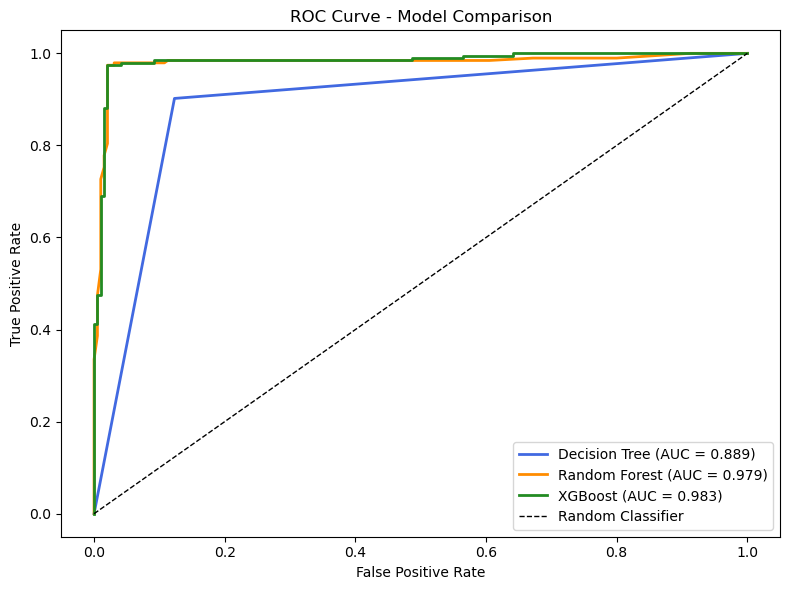

In [11]:
fig, ax = plt.subplots(figsize=(8, 6))
colors = ['royalblue', 'darkorange', 'forestgreen']

for (name, model), color in zip(models.items(), colors):
    y_prob = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc = roc_auc_score(y_test, y_prob)
    ax.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})', color=color, lw=2)

ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random Classifier')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve - Model Comparison')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('images/roc_curve.png', dpi=150)
plt.show()

### 8.3 Confusion Matrix
Visualize the breakdown of correct and incorrect predictions for each model. Pay attention to false negatives (missed suspicious transactions) which are costlier in fraud detection.


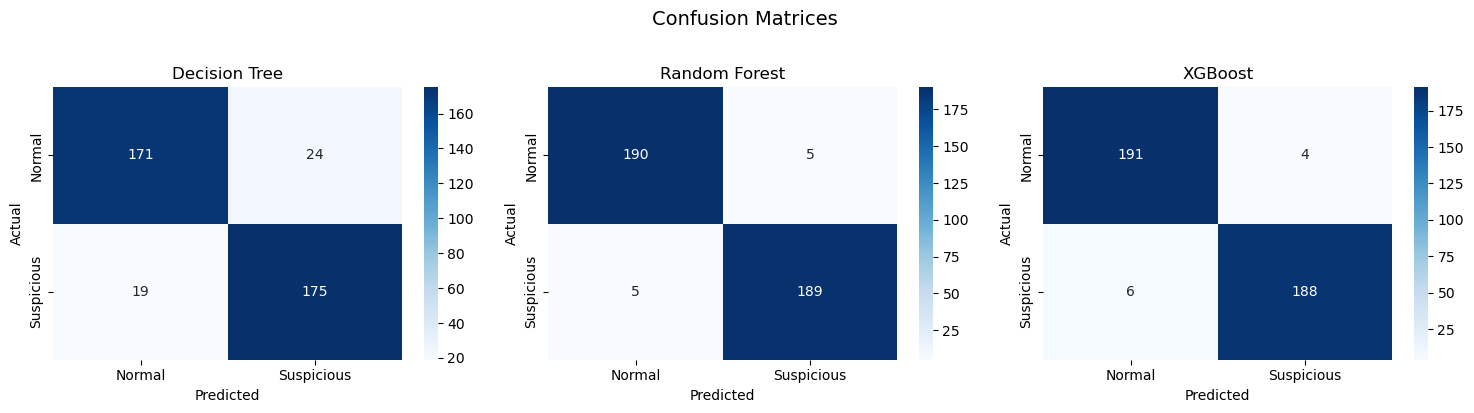

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=ax,
        xticklabels=['Normal', 'Suspicious'],
        yticklabels=['Normal', 'Suspicious']
    )
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.suptitle('Confusion Matrices', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('images/confusion_matrices.png', dpi=150)
plt.show()

### 8.4 Precision-Recall Curve
For imbalanced datasets like fraud detection, the **Precision-Recall (PR) curve** is more informative than ROC-AUC. It focuses on the minority class performance, showing how well the model identifies suspicious transactions without excessive false alarms.

> A high **Average Precision (AP)** score indicates the model maintains strong precision even at high recall levels.


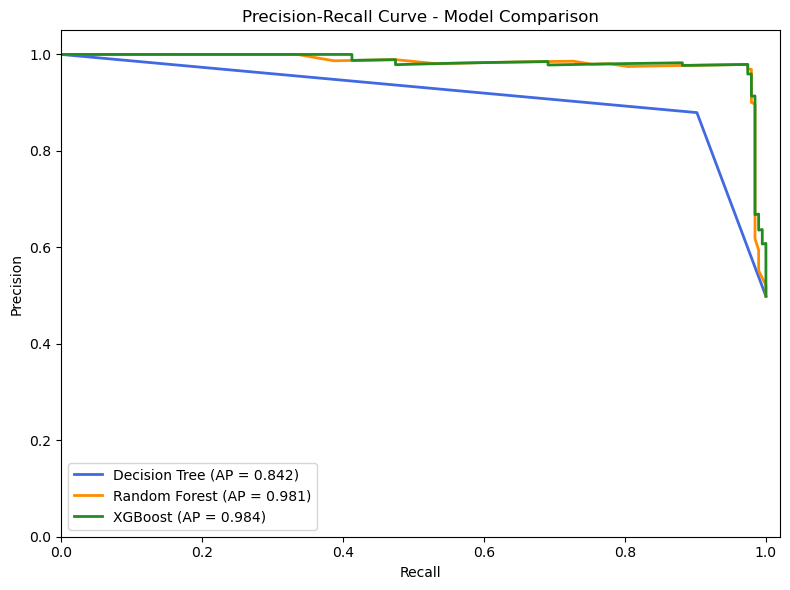

In [13]:
from sklearn.metrics import precision_recall_curve, average_precision_score

fig, ax = plt.subplots(figsize=(8, 6))
colors = ['royalblue', 'darkorange', 'forestgreen']

for (name, m), color in zip(models.items(), colors):
    y_prob = m.predict_proba(X_test)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, y_prob)
    ap = average_precision_score(y_test, y_prob)
    ax.plot(recall, precision, label=f'{name} (AP = {ap:.3f})', color=color, lw=2)

ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve - Model Comparison')
ax.legend(loc='lower left')
ax.set_xlim([0, 1.02])
ax.set_ylim([0, 1.05])
plt.tight_layout()
plt.savefig('images/precision_recall_curve.png', dpi=150)
plt.show()


### 8.5 Comprehensive Metrics Summary Table
Consolidate all evaluation metrics into a single comparison table for clear model benchmarking.


Model Performance Comparison
               Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC
Model                                                                
Decision Tree    0.8895     0.8794  0.9021    0.8906   0.8895  0.8421
Random Forest    0.9743     0.9742  0.9742    0.9742   0.9794  0.9810
XGBoost          0.9743     0.9792  0.9691    0.9741   0.9832  0.9836


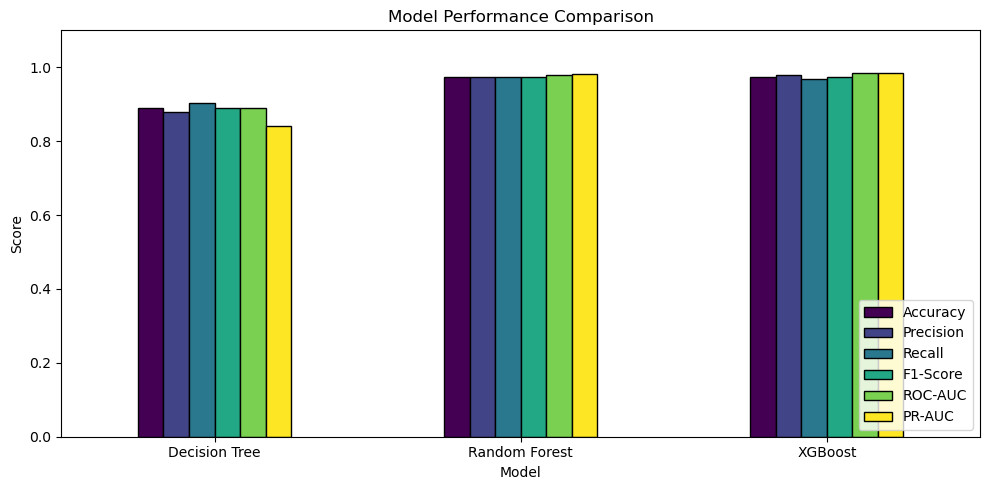

In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []
for name, m in models.items():
    y_pred = m.predict(X_test)
    y_prob = m.predict_proba(X_test)[:, 1]
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1-Score': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_prob),
        'PR-AUC': average_precision_score(y_test, y_prob)
    })

df_results = pd.DataFrame(results).set_index('Model')
print('Model Performance Comparison')
print('=' * 80)
print(df_results.round(4).to_string())

# Visual comparison
fig, ax = plt.subplots(figsize=(10, 5))
df_results.plot(kind='bar', ax=ax, colormap='viridis', edgecolor='black')
ax.set_title('Model Performance Comparison')
ax.set_ylabel('Score')
ax.set_xticklabels(df_results.index, rotation=0)
ax.set_ylim([0, 1.1])
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('images/model_comparison.png', dpi=150)
plt.show()


# **9. Hyperparameter Tuning - GridSearchCV**
Tune the **Random Forest** model (best trade-off between accuracy and stability).
Scoring metric changed to `roc_auc` which is more informative for imbalanced classification.


In [15]:
params = {
    'n_estimators'    : [100, 200, 300],
    'max_depth'       : [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10]
}

tuned_model = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=params,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)
tuned_model.fit(X_train_bal, y_train_bal)

print("Best parameters :", tuned_model.best_params_)
print("Best ROC-AUC    :", round(tuned_model.best_score_, 4))

Best parameters : {'max_depth': 20, 'min_samples_split': 10, 'n_estimators': 100}
Best ROC-AUC    : 0.9497


## 9.1 Tuned Model Evaluation

In [16]:
y_pred_tuned = tuned_model.predict(X_test)
y_prob_tuned = tuned_model.predict_proba(X_test)[:, 1]

print("Tuned Random Forest Performance")
print(classification_report(y_test, y_pred_tuned))
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_tuned):.4f}")

joblib.dump(tuned_model, 'models/tuned_random_forest_model.h5')
print("\nModel saved as tuned_random_forest_model.h5")

Tuned Random Forest Performance
              precision    recall  f1-score   support

           0       0.97      0.98      0.98       195
           1       0.98      0.97      0.98       194

    accuracy                           0.98       389
   macro avg       0.98      0.98      0.98       389
weighted avg       0.98      0.98      0.98       389

ROC-AUC: 0.9795

Model saved as tuned_random_forest_model.h5


# **10. Learning Curve Analysis**
The learning curve plots training and validation scores as a function of training set size. This diagnoses whether the model suffers from **overfitting** (large gap between curves) or **underfitting** (both curves plateau at low scores).

> A well-generalizing model shows both curves converging at a high score.


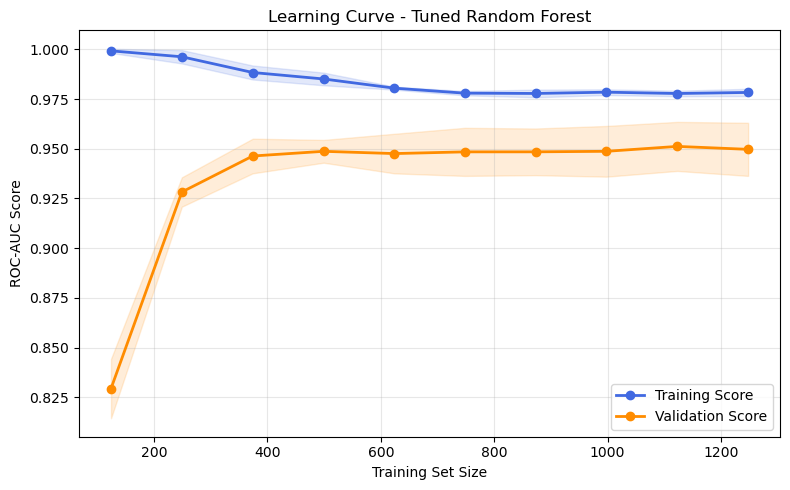

Final training score : 0.9783
Final validation score: 0.9497
Generalization gap   : 0.0286
Assessment: Model generalizes well (gap < 0.05).


In [17]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, val_scores = learning_curve(
    tuned_model.best_estimator_,
    X_train_bal, y_train_bal,
    cv=5,
    scoring='roc_auc',
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1,
    random_state=42
)

train_mean = train_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
val_mean   = val_scores.mean(axis=1)
val_std    = val_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(8, 5))
ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='royalblue')
ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15, color='darkorange')
ax.plot(train_sizes, train_mean, 'o-', color='royalblue', lw=2, label='Training Score')
ax.plot(train_sizes, val_mean, 'o-', color='darkorange', lw=2, label='Validation Score')
ax.set_xlabel('Training Set Size')
ax.set_ylabel('ROC-AUC Score')
ax.set_title('Learning Curve - Tuned Random Forest')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('images/learning_curve.png', dpi=150)
plt.show()

gap = train_mean[-1] - val_mean[-1]
print(f'Final training score : {train_mean[-1]:.4f}')
print(f'Final validation score: {val_mean[-1]:.4f}')
print(f'Generalization gap   : {gap:.4f}')
if gap < 0.05:
    print('Assessment: Model generalizes well (gap < 0.05).')
elif gap < 0.10:
    print('Assessment: Slight overfitting detected. Consider regularization.')
else:
    print('Assessment: Significant overfitting. Reduce model complexity.')


# **11. Explainability - SHAP Values**
Use **SHAP (SHapley Additive exPlanations)** to understand *why* the model makes each prediction.

- **Summary Plot** - shows global feature impact across all predictions
- Positive SHAP value → pushes prediction toward class 1 (Suspicious)
- Negative SHAP value → pushes prediction toward class 0 (Normal)

This is critical for the fraud team to understand and trust model decisions.


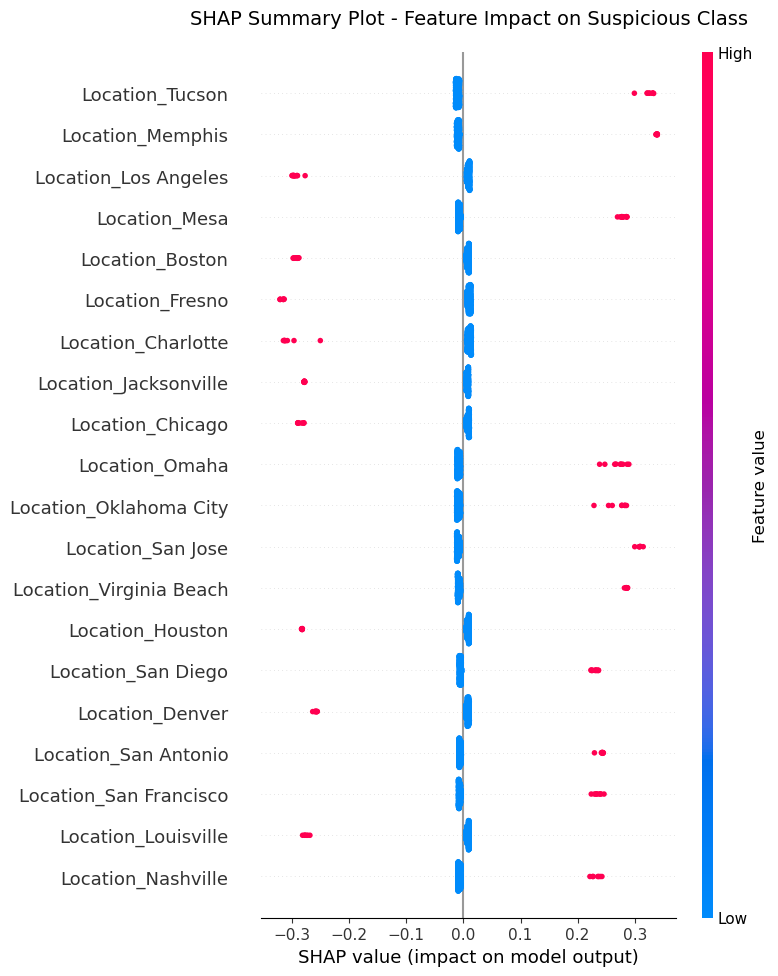

In [18]:
best_rf = tuned_model.best_estimator_
explainer = shap.TreeExplainer(best_rf)
shap_values = explainer.shap_values(X_test)

if isinstance(shap_values, list):
    shap_class1 = shap_values[1] 
else:
    shap_class1 = shap_values[:, :, 1] 

plt.figure(figsize=(10, 6)) 
shap.summary_plot(shap_class1, X_test, show=False)
plt.title('SHAP Summary Plot - Feature Impact on Suspicious Class', pad=20, fontsize=14)
plt.savefig('images/shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

# **12. Feature Importance (Random Forest)**
Identify which features contribute most to the model's predictions using built-in `feature_importances_`.


Top 10 Most Important Features:
               feature  importance
    Location_Charlotte    0.038799
       Location_Tucson    0.037672
       Location_Fresno    0.037185
      Location_Memphis    0.035500
     Location_San Jose    0.034023
  Location_Los Angeles    0.032799
Location_Oklahoma City    0.030867
      Location_Houston    0.030734
        Location_Omaha    0.030410
       Location_Boston    0.030383


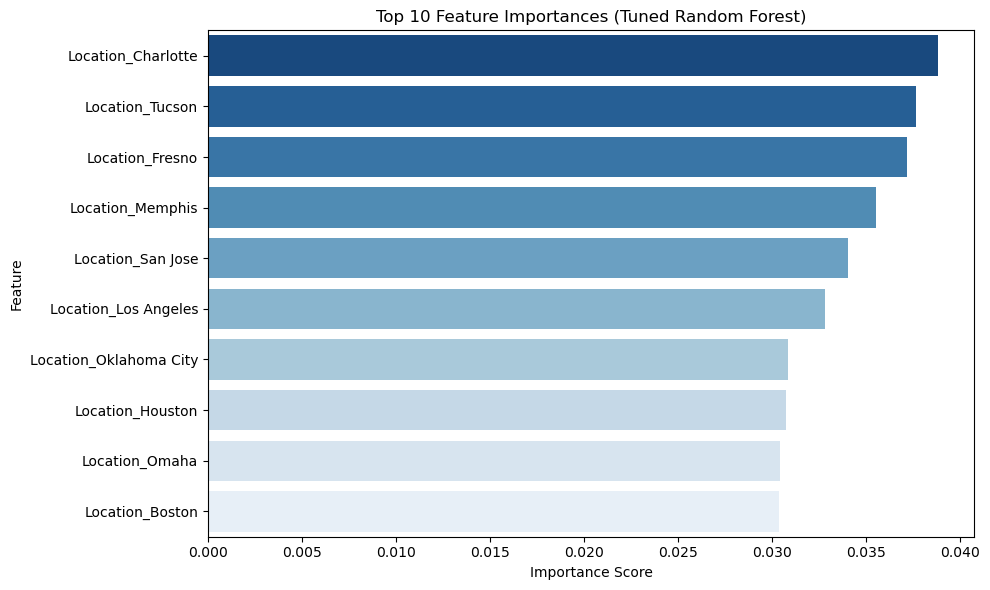

In [19]:
feat_imp = pd.DataFrame({
    'feature'   : X.columns,
    'importance': best_rf.feature_importances_
}).sort_values('importance', ascending=False).reset_index(drop=True)

print("Top 10 Most Important Features:")
print(feat_imp.head(10).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=feat_imp.head(10),
    x='importance', y='feature',
    palette='Blues_r', ax=ax
)
ax.set_title('Top 10 Feature Importances (Tuned Random Forest)')
ax.set_xlabel('Importance Score')
ax.set_ylabel('Feature')
plt.tight_layout()
plt.savefig('images/feature_importance.png', dpi=150)
plt.show()

# **13. Final Model Selection & Conclusion**
Select the best-performing model based on the comprehensive evaluation above, and summarize the key findings.


In [20]:
# Determine the best model based on ROC-AUC
best_model_name = df_results['ROC-AUC'].idxmax()
best_model_auc  = df_results.loc[best_model_name, 'ROC-AUC']
best_model_f1   = df_results.loc[best_model_name, 'F1-Score']

print('=' * 60)
print('  FINAL MODEL SELECTION')
print('=' * 60)
print(f'  Best Model   : {best_model_name}')
print(f'  ROC-AUC      : {best_model_auc:.4f}')
print(f'  F1-Score     : {best_model_f1:.4f}')
print('=' * 60)

# Compare tuned model performance
tuned_auc = roc_auc_score(y_test, y_prob_tuned)
print(f'\n  Tuned RF AUC : {tuned_auc:.4f}')

if tuned_auc > best_model_auc:
    print('  → Tuned Random Forest outperforms base models.')
    print('  → Recommended for production deployment.')
    final_model = tuned_model
    final_model_name = 'Tuned Random Forest'
else:
    print(f'  → {best_model_name} remains the top performer.')
    final_model = models[best_model_name]
    final_model_name = best_model_name

# Export final model with metadata
import datetime
model_metadata = {
    'model_name': final_model_name,
    'trained_at': str(datetime.datetime.now()),
    'features': list(X.columns),
    'n_features': len(X.columns),
    'roc_auc': round(best_model_auc if final_model_name == best_model_name else tuned_auc, 4),
    'n_train_samples': len(X_train_bal),
    'n_test_samples': len(X_test)
}

joblib.dump({'model': final_model, 'metadata': model_metadata}, 'models/final_classification_model.h5')
print(f'\n  Model exported: models/final_classification_model.h5')
print(f'  Metadata: {model_metadata}')


  FINAL MODEL SELECTION
  Best Model   : XGBoost
  ROC-AUC      : 0.9832
  F1-Score     : 0.9741

  Tuned RF AUC : 0.9795
  → XGBoost remains the top performer.

  Model exported: models/final_classification_model.h5
  Metadata: {'model_name': 'XGBoost', 'trained_at': '2026-04-30 20:49:58.739343', 'features': ['CustomerAge', 'TransactionDuration', 'LoginAttempts', 'TransactionType_Debit', 'Location_Atlanta', 'Location_Austin', 'Location_Baltimore', 'Location_Boston', 'Location_Charlotte', 'Location_Chicago', 'Location_Colorado Springs', 'Location_Columbus', 'Location_Dallas', 'Location_Denver', 'Location_Detroit', 'Location_El Paso', 'Location_Fort Worth', 'Location_Fresno', 'Location_Houston', 'Location_Indianapolis', 'Location_Jacksonville', 'Location_Kansas City', 'Location_Las Vegas', 'Location_Los Angeles', 'Location_Louisville', 'Location_Memphis', 'Location_Mesa', 'Location_Miami', 'Location_Milwaukee', 'Location_Nashville', 'Location_New York', 'Location_Oklahoma City', 'Locati

# **14. Prediction Pipeline Demo**
Demonstrate how to load the saved model and make predictions on new data. This section serves as a reference for deployment or integration into a production system.


In [21]:
# Load the exported model
loaded = joblib.load('models/final_classification_model.h5')
loaded_model = loaded['model']
loaded_meta  = loaded['metadata']

print('Loaded Model Info:')
print(f"  Name     : {loaded_meta['model_name']}")
print(f"  Trained  : {loaded_meta['trained_at']}")
print(f"  Features : {loaded_meta['n_features']}")
print(f"  ROC-AUC  : {loaded_meta['roc_auc']}")

# Predict on a sample from the test set
sample = X_test.head(5)
predictions = loaded_model.predict(sample)
probabilities = loaded_model.predict_proba(sample)[:, 1]

demo_results = pd.DataFrame({
    'Prediction': ['Normal' if p == 0 else 'Suspicious' for p in predictions],
    'Probability (Suspicious)': [f'{p:.2%}' for p in probabilities],
    'Actual': ['Normal' if a == 0 else 'Suspicious' for a in y_test.head(5).values]
})

print('\nSample Predictions:')
print(demo_results.to_string(index=False))


Loaded Model Info:
  Name     : XGBoost
  Trained  : 2026-04-30 20:49:58.739343
  Features : 53
  ROC-AUC  : 0.9832

Sample Predictions:
Prediction Probability (Suspicious)     Actual
Suspicious                   95.09% Suspicious
Suspicious                   98.05% Suspicious
    Normal                    5.85%     Normal
    Normal                    2.43%     Normal
    Normal                   31.02%     Normal
